In [2]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix


In [4]:
df = pd.read_csv("nlp_dataset.csv")

df.head()

,Comment,Emotion
0,i seriously hate one subject to death but now ...,fear
1,im so full of life i feel appalled,anger
2,i sit here to write i start to dig out my feel...,fear
3,ive been really angry with r and i feel like a...,joy
4,i feel suspicious if there is no one outside l...,fear


In [5]:
print(df.info())
print("Dataset Shape:", df.shape)
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

print(df["Emotion"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 5937 entries, 0 to 5936
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Comment  5937 non-null   str  
 1   Emotion  5937 non-null   str  
dtypes: str(2)
memory usage: 92.9 KB
None
Dataset Shape: (5937, 2)
Comment    0
Emotion    0
dtype: int64
Duplicates: 0
Emotion
anger    2000
joy      2000
fear     1937
Name: count, dtype: int64


In [6]:
df = df.dropna()
df = df.drop_duplicates()

print("Dataset after cleaning:", df.shape)

Dataset after cleaning: (5937, 2)


In [7]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

stop_words = set(stopwords.words('english'))

# Keep important negation words
stop_words = stop_words - {'not', 'no', 'nor'}

def clean_text(text):

    text = text.lower()

    text = re.sub(r'[^a-z\s]', '', text)

    words = word_tokenize(text)

    words = [word for word in words if word not in stop_words]

    return ' '.join(words)


df['Cleaned_Comment'] = df['Comment'].apply(clean_text)

df[['Comment', 'Cleaned_Comment', 'Emotion']].head()

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,Comment,Cleaned_Comment,Emotion
0,i seriously hate one subject to death but now ...,seriously hate one subject death feel reluctan...,fear
1,im so full of life i feel appalled,im full life feel appalled,anger
2,i sit here to write i start to dig out my feel...,sit write start dig feelings think afraid acce...,fear
3,ive been really angry with r and i feel like a...,ive really angry r feel like idiot trusting fi...,joy
4,i feel suspicious if there is no one outside l...,feel suspicious no one outside like rapture ha...,fear


In [8]:
X = df['Cleaned_Comment']
y = df['Emotion']

tfidf = TfidfVectorizer()

X = tfidf.fit_transform(X)

print("TF-IDF Shape:", X.shape)

TF-IDF Shape: (5937, 8818)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4749, 8818)
Testing Data: (1188, 8818)


In [10]:
nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

nb_predictions = nb_model.predict(X_test)

print("Naive Bayes Accuracy:",
      accuracy_score(y_test, nb_predictions))

print("\nClassification Report:")
print(classification_report(y_test, nb_predictions))

Naive Bayes Accuracy: 0.8905723905723906

Classification Report:
              precision    recall  f1-score   support

       anger       0.88      0.91      0.89       400
        fear       0.87      0.91      0.89       388
         joy       0.93      0.86      0.89       400

    accuracy                           0.89      1188
   macro avg       0.89      0.89      0.89      1188
weighted avg       0.89      0.89      0.89      1188



In [11]:
svm_model = LinearSVC()

svm_model.fit(X_train, y_train)

svm_predictions = svm_model.predict(X_test)

print("SVM Accuracy:",
      accuracy_score(y_test, svm_predictions))

print("\nClassification Report:")
print(classification_report(y_test, svm_predictions))

SVM Accuracy: 0.9377104377104377

Classification Report:
              precision    recall  f1-score   support

       anger       0.94      0.93      0.94       400
        fear       0.94      0.93      0.94       388
         joy       0.93      0.95      0.94       400

    accuracy                           0.94      1188
   macro avg       0.94      0.94      0.94      1188
weighted avg       0.94      0.94      0.94      1188



In [12]:
nb_accuracy = accuracy_score(y_test, nb_predictions)

svm_accuracy = accuracy_score(y_test, svm_predictions)

results = pd.DataFrame({
    'Model': ['Naive Bayes', 'SVM'],
    'Accuracy': [nb_accuracy, svm_accuracy]
})

print(results)

         Model  Accuracy
0  Naive Bayes  0.890572
1          SVM  0.937710


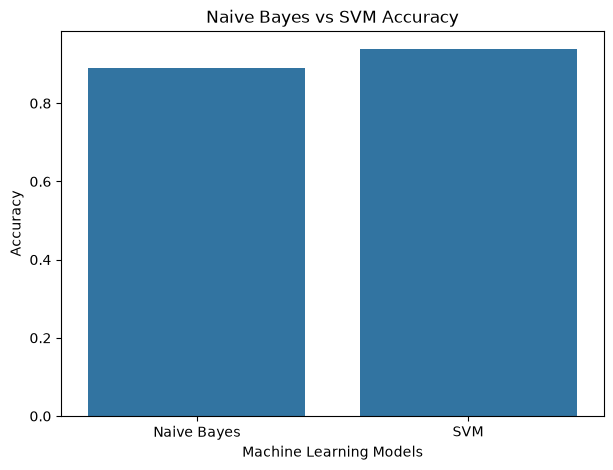

In [13]:
plt.figure(figsize=(7, 5))

sns.barplot(data=results, x='Model', y='Accuracy')

plt.title('Naive Bayes vs SVM Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Machine Learning Models')

plt.show()

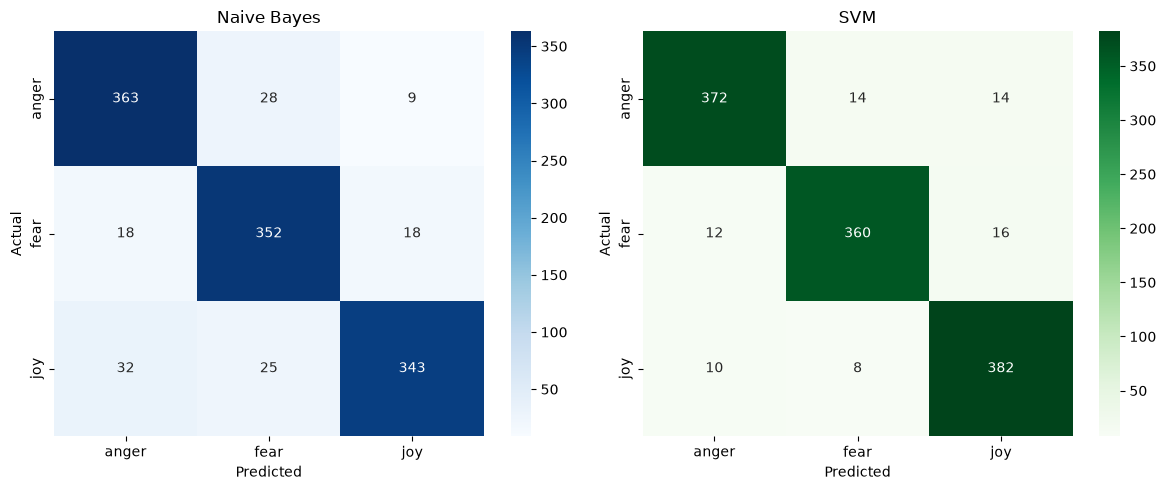

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

labels = sorted(y_test.unique())

sns.heatmap(
    confusion_matrix(y_test, nb_predictions, labels=labels),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[0]
)

axes[0].set_title('Naive Bayes')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(
    confusion_matrix(y_test, svm_predictions, labels=labels),
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[1]
)

axes[1].set_title('SVM')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [15]:
if nb_accuracy > svm_accuracy:
    print("Naive Bayes performs better.")

elif svm_accuracy > nb_accuracy:
    print("SVM performs better.")

else:
    print("Both models have equal accuracy.")

SVM performs better.


Conclusion:

In this assignment, we developed a Sentiment Analysis model to classify emotions in text comments.

The dataset was preprocessed using lowercase conversion, text cleaning, tokenization and stopword removal.

TF-IDF was used to convert text data into numerical features.

Two machine learning algorithms were implemented:
1. Naive Bayes
2. Support Vector Machine (SVM)
Both models were evaluated using accuracy, precision, recall, F1-score and confusion matrices.